# Preprocessing Dataset Kematangan Buah Sawit (YOLOv11 & Faster R-CNN)

Notebook ini mendokumentasikan tahap **Obtain–Scrub–Explore–Transform** dalam kerangka OSEMN untuk dataset deteksi tingkat kematangan buah sawit. Tujuannya bukan melatih model, melainkan memastikan data yang masuk ke YOLOv11 dan Faster R-CNN memiliki kelas, split, dan representasi bounding box yang konsisten.

Alur kerja: (1) unduh data dan baca metadata, (2) audit file gambar serta anotasi, (3) ubah seluruh label ke bounding box deteksi standar, (4) eksplorasi distribusi dan kualitas visual, (5) ekspor COCO untuk Faster R-CNN, lalu (6) verifikasi konsistensi hasil ekspor. File sumber tidak dihapus atau diubah; hasil standardisasi disimpan terpisah.


## 1. Setup & Obtain — Google Colab + Roboflow

Bagian ini menyiapkan pustaka, mengunduh versi 3 proyek Roboflow dalam format `yolov11`, lalu mendefinisikan lokasi data dan folder keluaran. Setelah sel selesai, variabel `DATASET_DIR` harus menunjuk ke folder dataset yang berhasil diekstrak, sedangkan seluruh laporan preprocessing akan disimpan di `OUTPUT_DIR`.

Notebook dirancang untuk Google Colab. Isi API key saat prompt muncul dan jangan menaruhnya di sel kode atau membagikan salinan notebook yang berisi key. Karena `/content` bersifat sementara, simpan arsip keluaran sebelum runtime Colab berakhir.


In [ ]:
%pip install -q roboflow pyyaml pandas matplotlib pillow tqdm

from pathlib import Path
from collections import Counter, defaultdict
from datetime import datetime, timezone
from getpass import getpass
import hashlib
import json

import matplotlib.pyplot as plt
import pandas as pd
import yaml
from PIL import Image, ImageDraw
from roboflow import Roboflow

ROBOFLOW_API_KEY = getpass("Roboflow API key: ")
rf = Roboflow(api_key=ROBOFLOW_API_KEY)
project = rf.workspace("zah").project("palm-oil-fg85a")
version = project.version(3)
dataset = version.download("yolov11")
DATASET_DIR = Path(dataset.location)

COLAB_WORK_DIR = Path("/content/palm_oil_model_comparison")
OUTPUT_DIR = COLAB_WORK_DIR / "preprocessing_output"
SPLITS = {"train": "train", "val": "valid", "test": "test"}
RANDOM_SEED = 42
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
assert DATASET_DIR.exists(), f"Dataset tidak ditemukan: {DATASET_DIR}"
print(f"Dataset berhasil diunduh: {DATASET_DIR}")
print(f"Output preprocessing: {OUTPUT_DIR}")

Roboflow API key: ··········
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to palm-oil-3 in yolov11:: 100%|██████████| 16804/16804 [00:12<00:00, 1388.86it/s]


Dataset berhasil diunduh: /content/palm-oil-3
Output preprocessing: /content/palm_oil_model_comparison/preprocessing_output


### Setup dan unduhan

Pesan `Dataset berhasil diunduh` menunjukkan dataset tersedia dan path tersebut akan dipakai oleh seluruh sel berikutnya. Pesan `Output preprocessing` menunjukkan lokasi semua artefak baru. Progress bar unduhan/ekstraksi hanya mengonfirmasi proses transfer; yang penting adalah kedua path tercetak tanpa error.


## 2. Obtain — Baca metadata dan tetapkan class mapping

Sel berikut membaca `data.yaml` untuk mengambil nama serta urutan empat kelas. Pada YOLO, ID kelas dimulai dari 0. Pada COCO/Faster R-CNN, kategori objek dimulai dari 1 karena ID 0 dipakai internal sebagai **background**. Mapping dibuat otomatis dari metadata agar tidak ada perubahan arti kelas pada saat konversi.


In [ ]:
with open(DATASET_DIR / "data.yaml", encoding="utf-8") as f:
    dataset_yaml = yaml.safe_load(f)

CLASS_NAMES = list(dataset_yaml["names"])
NUM_CLASSES = len(CLASS_NAMES)
assert dataset_yaml["nc"] == NUM_CLASSES == 4
YOLO_TO_COCO = {yolo_id: yolo_id + 1 for yolo_id in range(NUM_CLASSES)}
COCO_TO_NAME = {coco_id: CLASS_NAMES[coco_id - 1] for coco_id in range(1, NUM_CLASSES + 1)}

mapping = pd.DataFrame({
    "yolo_id": range(NUM_CLASSES),
    "class_name": CLASS_NAMES,
    "coco_category_id": range(1, NUM_CLASSES + 1),
})
display(mapping)
mapping.to_csv(OUTPUT_DIR / "class_mapping_yolo_to_coco.csv", index=False)
print("Sumber mapping: data.yaml")

,yolo_id,class_name,coco_category_id
0,0,kurang masak,1
1,1,masak,2
2,2,mentah,3
3,3,terlalu masak,4


Sumber mapping: data.yaml


### Mapping kelas

Tabel memperlihatkan empat kelas dengan urutan: `kurang masak` (YOLO 0/COCO 1), `masak` (1/2), `mentah` (2/3), dan `terlalu masak` (3/4). Kesepadanan satu-banding-satu ini harus dipertahankan pada konfigurasi model, pembacaan prediksi, dan evaluasi. Pesan `Sumber mapping: data.yaml` menegaskan mapping tidak dibuat berdasarkan asumsi manual.


## 3. Scrub — Audit struktur, resolusi, dan label bounding box

Audit memeriksa apakah setiap gambar memiliki label pasangan, apakah ada label tanpa gambar, serta apakah setiap baris anotasi memiliki geometri YOLO yang valid. Dataset dapat berisi anotasi bbox lima kolom atau poligon; poligon dihitung menjadi bounding box pembungkus minimum untuk analisis berikutnya.

Selain integritas label, audit merekam jumlah gambar, jumlah objek, dan ukuran gambar per split. Tidak ada file yang dihapus otomatis. Jika ditemukan masalah, detailnya ditulis ke `data_issues.csv` dan proses dihentikan agar data tidak diteruskan ke training dalam keadaan tidak konsisten.


In [ ]:
VALID_IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def parse_yolo_label(label_path, return_kinds=False):
    """Read bbox or polygon YOLO rows and return normalized detection bounding boxes."""
    boxes, kinds = [], Counter()
    with label_path.open(encoding="utf-8") as f:
        for line_no, line in enumerate(f, start=1):
            values = line.split()
            if not values:
                continue
            class_id = int(values[0])
            if class_id not in range(NUM_CLASSES):
                raise ValueError(f"{label_path.name}:{line_no}: class_id {class_id} is outside 0..{NUM_CLASSES - 1}")
            coordinates = list(map(float, values[1:]))
            if len(values) == 5:  # YOLO detection: class, x_center, y_center, width, height
                x_center, y_center, width, height = coordinates
                kind = "bbox"
            elif len(values) > 5 and len(coordinates) % 2 == 0:  # YOLO segmentation polygon
                xs, ys = coordinates[0::2], coordinates[1::2]
                x_min, x_max = min(xs), max(xs)
                y_min, y_max = min(ys), max(ys)
                x_center, y_center = (x_min + x_max) / 2, (y_min + y_max) / 2
                width, height = x_max - x_min, y_max - y_min
                kind = "polygon_to_bbox"
            else:
                raise ValueError(f"{label_path.name}:{line_no}: unsupported YOLO row with {len(values)} values")
            if not (0 < width <= 1 and 0 < height <= 1 and 0 <= x_center <= 1 and 0 <= y_center <= 1):
                raise ValueError(f"{label_path.name}:{line_no}: invalid normalized geometry")
            boxes.append((class_id, x_center, y_center, width, height))
            kinds[kind] += 1
    return (boxes, kinds) if return_kinds else boxes

audit_rows, issues, annotation_kinds = [], [], Counter()
for model_split, disk_split in SPLITS.items():
    image_dir, label_dir = DATASET_DIR / disk_split / "images", DATASET_DIR / disk_split / "labels"
    images = sorted(p for p in image_dir.iterdir() if p.suffix.lower() in VALID_IMAGE_SUFFIXES)
    labels = {p.stem: p for p in label_dir.glob("*.txt")}
    image_stems = {p.stem for p in images}
    for orphan in sorted(set(labels) - image_stems):
        issues.append({"split": model_split, "file": labels[orphan].name, "issue": "orphan_label"})
    for image_path in images:
        label_path = labels.get(image_path.stem)
        if label_path is None:
            issues.append({"split": model_split, "file": image_path.name, "issue": "missing_label"})
            continue
        try:
            with Image.open(image_path) as im:
                width, height = im.size
            boxes, kinds = parse_yolo_label(label_path, return_kinds=True)
            annotation_kinds.update(kinds)
            audit_rows.append({"split": model_split, "image": image_path.name, "width": width, "height": height, "boxes": len(boxes), "is_640x640": (width, height) == (640, 640)})
        except Exception as exc:
            issues.append({"split": model_split, "file": image_path.name, "issue": str(exc)})

audit_df, issues_df = pd.DataFrame(audit_rows), pd.DataFrame(issues)
audit_df.to_csv(OUTPUT_DIR / "image_audit.csv", index=False)
issues_df.to_csv(OUTPUT_DIR / "data_issues.csv", index=False)
print(audit_df.groupby("split").agg(images=("image", "count"), boxes=("boxes", "sum"), non_640=("is_640x640", lambda s: (~s).sum())))
print(f"Annotation sources: {dict(annotation_kinds)}")
print(f"Issue records: {len(issues_df)}")
if len(issues_df):
    display(issues_df.head(20))
assert len(issues_df) == 0, "Masih ada masalah struktur label. Periksa data_issues.csv."

       images  boxes  non_640
split                        
test      827   1355        0
train    5893   9266        0
val      1676   2654        0
Annotation sources: {'bbox': 13072, 'polygon_to_bbox': 203}
Issue records: 0


### Hasil audit

Audit menemukan **5.893** gambar/ **9.266** objek pada train, **1.676**/ **2.654** pada validasi, dan **827**/ **1.355** pada test. Semua gambar berukuran 640×640 (`non_640 = 0`) dan tidak ada catatan masalah (`Issue records: 0`), sehingga struktur file dan geometri label lolos pemeriksaan.

Sebanyak **13.072** anotasi sudah berupa bbox dan **203** anotasi poligon akan dikonversi menjadi bbox. Konversi ini penting agar seluruh **13.275** objek dapat dipakai konsisten oleh kedua model.


## 3b. Standardisasi label YOLO Detection

Dataset sumber memuat campuran anotasi bbox dan poligon. Sel ini menghasilkan salinan label dengan format deteksi YOLO yang seragam: `class_id x_center y_center width height`, semuanya ternormalisasi 0–1. Untuk anotasi poligon, nilai bbox dibuat dari titik paling kiri, kanan, atas, dan bawah poligon.

Gambar tidak diubah. Folder `yolo_detection_ready` hanya berisi referensi/salinan gambar dan label standar. Gunakan `data_yolo_detection_ready.yaml` saat melatih YOLOv11 supaya representasi labelnya sama dengan yang dikonversi ke COCO untuk Faster R-CNN.


In [ ]:
import os
import shutil

CLEAN_YOLO_DIR = COLAB_WORK_DIR / "yolo_detection_ready"
for model_split, disk_split in SPLITS.items():
    clean_split = CLEAN_YOLO_DIR / model_split
    clean_images = clean_split / "images"
    clean_labels = clean_split / "labels"
    clean_labels.mkdir(parents=True, exist_ok=True)
    source_images = DATASET_DIR / disk_split / "images"
    if not clean_images.exists():
        try:
            clean_images.symlink_to(source_images, target_is_directory=True)
        except OSError:
            shutil.copytree(source_images, clean_images)
    for label_path in sorted((DATASET_DIR / disk_split / "labels").glob("*.txt")):
        boxes = parse_yolo_label(label_path)
        clean_label_path = clean_labels / label_path.name
        with clean_label_path.open("w", encoding="utf-8") as f:
            for class_id, xc, yc, bw, bh in boxes:
                f.write(f"{class_id} {xc:.8f} {yc:.8f} {bw:.8f} {bh:.8f}\n")

YOLO_DATA_YAML = CLEAN_YOLO_DIR / "data_yolo_detection_ready.yaml"
yolo_ready_config = {
    "path": str(CLEAN_YOLO_DIR),
    "train": "train/images", "val": "val/images", "test": "test/images",
    "nc": NUM_CLASSES, "names": CLASS_NAMES,
}
with YOLO_DATA_YAML.open("w", encoding="utf-8") as f:
    yaml.safe_dump(yolo_ready_config, f, allow_unicode=True, sort_keys=False)
print(f"YOLO detection-ready YAML: {YOLO_DATA_YAML}")
print("Gunakan file YAML ini, bukan data.yaml sumber, saat training YOLOv11.")

YOLO detection-ready YAML: /content/palm_oil_model_comparison/yolo_detection_ready/data_yolo_detection_ready.yaml
Gunakan file YAML ini, bukan data.yaml sumber, saat training YOLOv11.


### Label YOLO siap pakai

Path yang tercetak adalah YAML konfigurasi baru untuk training YOLOv11. Gunakan file ini sebagai argumen `data` pada perintah training, bukan `data.yaml` sumber, karena YAML baru menunjuk ke label yang telah diseragamkan. Sel ini tidak mengubah dataset Roboflow asli.


# 4. Explore (EDA) — Karakteristik dataset deteksi

EDA memakai bounding box hasil standardisasi: bbox sumber tetap dipakai, sedangkan poligon direpresentasikan oleh bounding box pembungkusnya. Oleh karena itu, hasil statistik ini menjelaskan input yang akan diterima oleh kedua eksperimen model, bukan hanya salah satunya.

Fokus EDA adalah kecukupan split, keseimbangan kelas, jumlah objek per gambar, ukuran serta bentuk objek, posisi objek, kondisi warna/kecerahan, dan potensi duplikasi lintas split. Temuan EDA dipakai untuk mengidentifikasi risiko sebelum training—bukan untuk mengubah data secara otomatis.


In [ ]:
# Bentuk tabel analitis satu baris per bounding box dan satu baris per gambar.
bbox_records, image_records = [], []
for model_split, disk_split in SPLITS.items():
    image_dir = DATASET_DIR / disk_split / "images"
    label_dir = DATASET_DIR / disk_split / "labels"
    for image_path in sorted(p for p in image_dir.iterdir() if p.suffix.lower() in VALID_IMAGE_SUFFIXES):
        with Image.open(image_path) as im:
            image_width, image_height = im.size
        boxes = parse_yolo_label(label_dir / f"{image_path.stem}.txt")
        image_records.append({
            "split": model_split, "image": image_path.name,
            "width": image_width, "height": image_height, "objects": len(boxes),
        })
        for class_id, xc, yc, bw, bh in boxes:
            bbox_records.append({
                "split": model_split, "image": image_path.name,
                "class_id": class_id, "class_name": CLASS_NAMES[class_id],
                "x_center_norm": xc, "y_center_norm": yc,
                "width_norm": bw, "height_norm": bh,
                "area_ratio": bw * bh, "aspect_ratio": bw / bh,
                "bbox_area_px": bw * bh * image_width * image_height,
            })

bbox_eda_df = pd.DataFrame(bbox_records)
image_eda_df = pd.DataFrame(image_records)
bbox_eda_df.to_csv(OUTPUT_DIR / "eda_bounding_boxes.csv", index=False)
image_eda_df.to_csv(OUTPUT_DIR / "eda_images.csv", index=False)

split_summary = image_eda_df.groupby("split").agg(
    images=("image", "count"),
    objects=("objects", "sum"),
    mean_objects_per_image=("objects", "mean"),
    median_objects_per_image=("objects", "median"),
).round(3)
display(split_summary)
split_summary.to_csv(OUTPUT_DIR / "eda_split_summary.csv")

class_split_table = pd.crosstab(bbox_eda_df["class_name"], bbox_eda_df["split"]).reindex(CLASS_NAMES, fill_value=0)
display(class_split_table)
class_split_table.to_csv(OUTPUT_DIR / "eda_class_by_split.csv")

,images,objects,mean_objects_per_image,median_objects_per_image
split,,,,
test,827,1355,1.638,2.0
train,5893,9266,1.572,1.0
val,1676,2654,1.584,1.0


split,test,train,val
class_name,,,
kurang masak,394,2635,757
masak,271,1959,556
mentah,362,2447,705
terlalu masak,328,2225,636


### Ukuran split dan sebaran kelas

Jumlah gambar dan objek relatif proporsional di seluruh split: rata-rata sekitar **1,57–1,64 objek per gambar**. Split test sedikit lebih padat (median 2 objek per gambar) dibanding train dan validasi (median 1), tetapi perbedaannya kecil.

Pada setiap split, kelas `masak` adalah yang paling sedikit, sedangkan `kurang masak` paling banyak. Ketimpangannya moderat, bukan ekstrem; namun metrik per kelas (misalnya AP per kelas) tetap perlu dilaporkan agar performa kelas `masak` tidak tertutup oleh rata-rata keseluruhan.


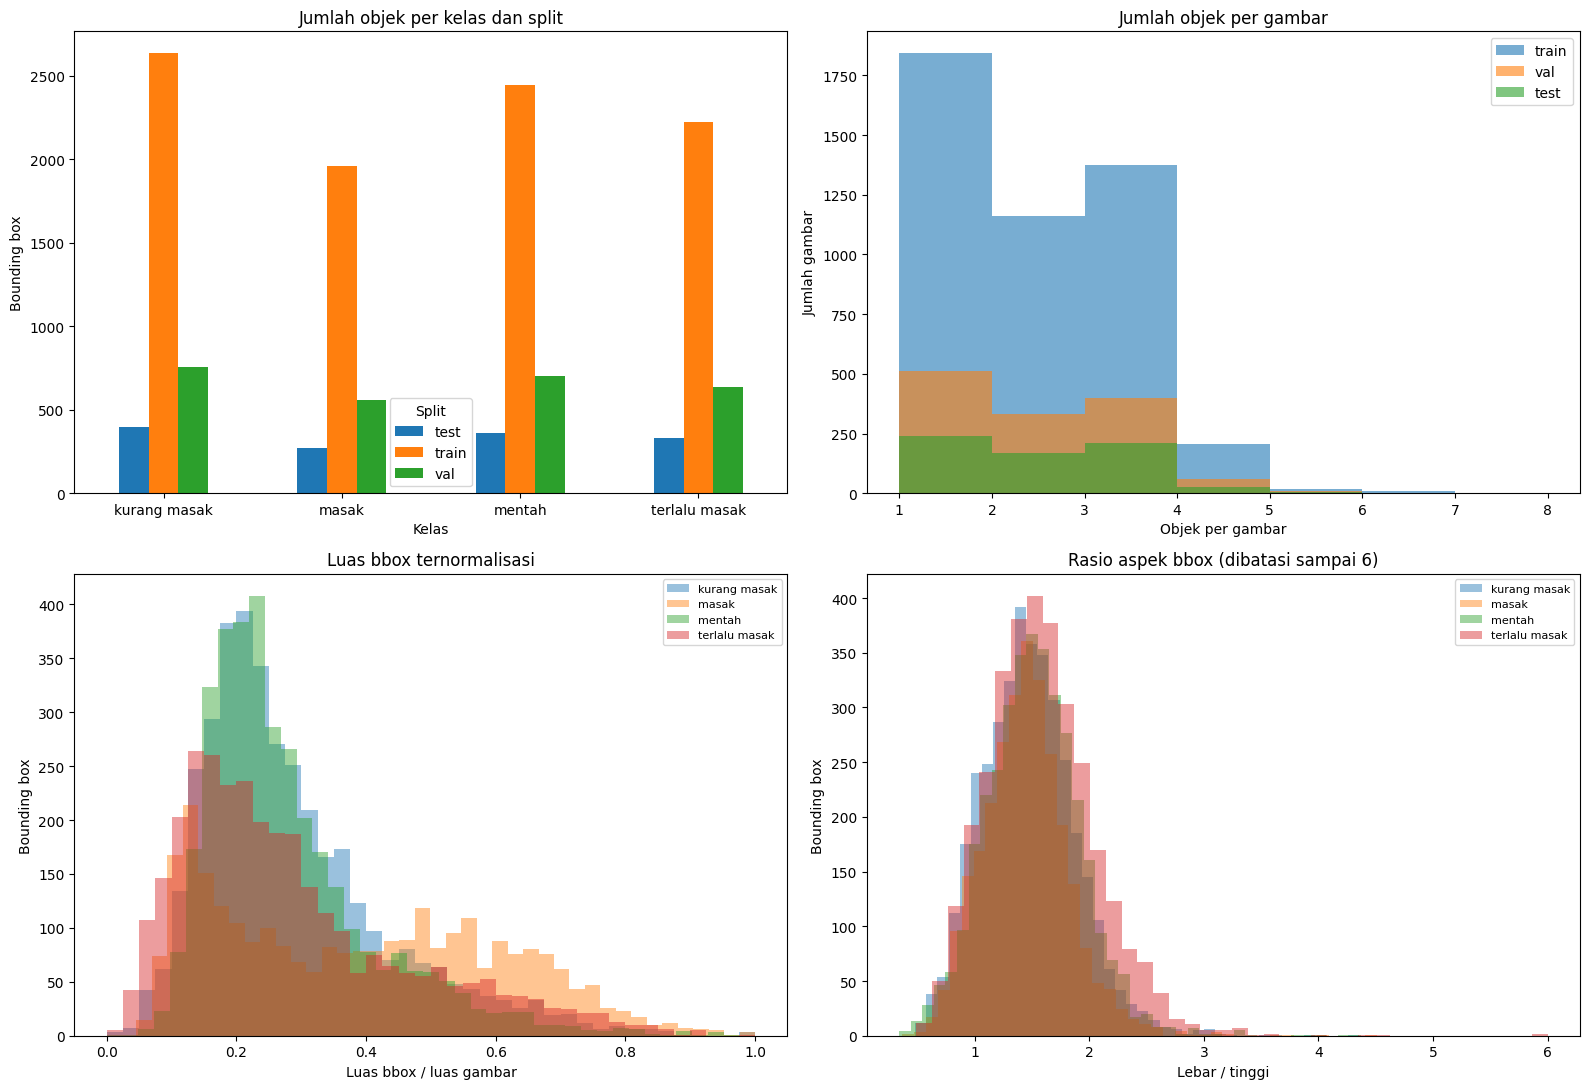

In [ ]:
# Distribusi kelas, kepadatan objek, ukuran bbox, dan rasio bentuk bbox.
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

class_split_table.plot(kind="bar", ax=axes[0, 0], rot=0)
axes[0, 0].set(title="Jumlah objek per kelas dan split", xlabel="Kelas", ylabel="Bounding box")
axes[0, 0].legend(title="Split")

for split in SPLITS:
    axes[0, 1].hist(image_eda_df.loc[image_eda_df.split == split, "objects"], bins=range(1, int(image_eda_df.objects.max()) + 2), alpha=0.6, label=split)
axes[0, 1].set(title="Jumlah objek per gambar", xlabel="Objek per gambar", ylabel="Jumlah gambar")
axes[0, 1].legend()

for class_name in CLASS_NAMES:
    values = bbox_eda_df.loc[bbox_eda_df.class_name == class_name, "area_ratio"]
    axes[1, 0].hist(values, bins=40, alpha=0.45, label=class_name)
axes[1, 0].set(title="Luas bbox ternormalisasi", xlabel="Luas bbox / luas gambar", ylabel="Bounding box")
axes[1, 0].legend(fontsize=8)

for class_name in CLASS_NAMES:
    values = bbox_eda_df.loc[bbox_eda_df.class_name == class_name, "aspect_ratio"].clip(upper=6)
    axes[1, 1].hist(values, bins=40, alpha=0.45, label=class_name)
axes[1, 1].set(title="Rasio aspek bbox (dibatasi sampai 6)", xlabel="Lebar / tinggi", ylabel="Bounding box")
axes[1, 1].legend(fontsize=8)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "eda_annotation_distributions.png", dpi=180, bbox_inches="tight")
plt.show()

### Grafik distribusi anotasi

Empat grafik membantu membaca risiko data sebelum training. Grafik kelas memperlihatkan apakah ketimpangan kelas konsisten pada semua split; histogram objek per gambar menunjukkan kepadatan adegan; histogram luas bbox menunjukkan proporsi objek kecil/besar; dan rasio aspek menunjukkan bentuk kotak yang paling umum.

Perhatikan ekor distribusi luas bbox yang sangat kecil atau rasio aspek yang ekstrem. Jika jumlahnya besar, model dapat lebih sulit mendeteksi objek kecil atau bentuk tidak lazim. Batas rasio aspek hingga 6 hanya dipakai agar grafik mudah dibaca—data asli tidak dihapus atau dipotong.


This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


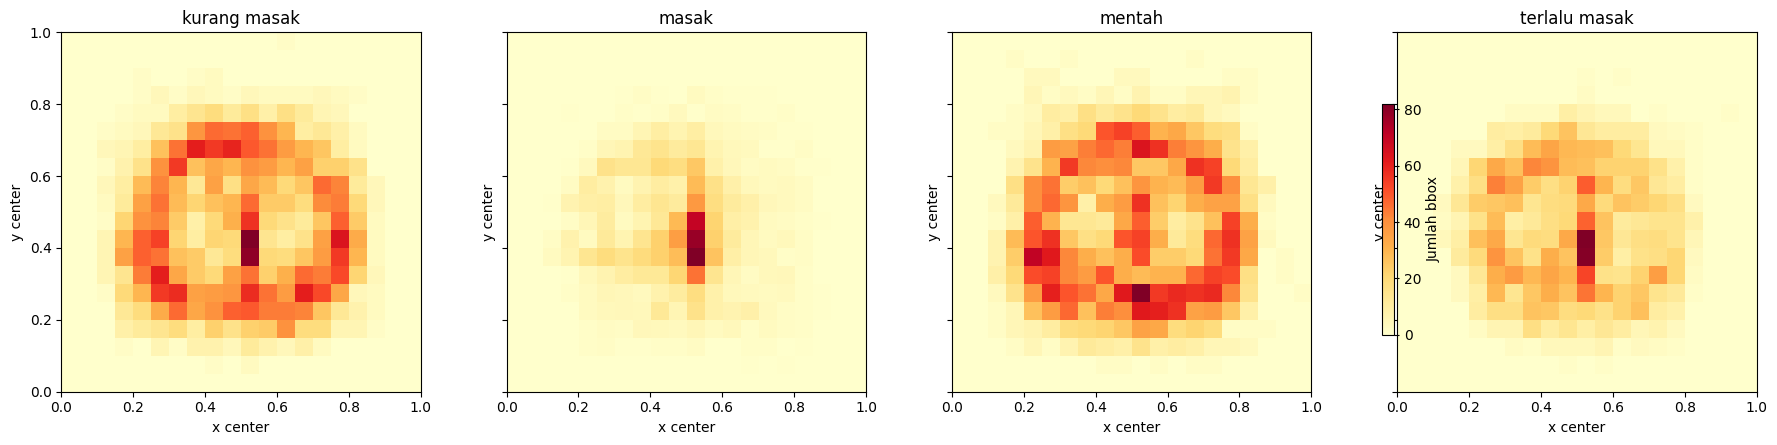

In [ ]:
# Posisi pusat bbox membantu mendeteksi bias posisi objek pada citra.
import numpy as np

fig, axes = plt.subplots(1, NUM_CLASSES, figsize=(18, 4), sharex=True, sharey=True)
for ax, class_name in zip(axes, CLASS_NAMES):
    subset = bbox_eda_df[bbox_eda_df.class_name == class_name]
    heatmap, x_edges, y_edges = np.histogram2d(subset.x_center_norm, subset.y_center_norm, bins=20, range=[[0, 1], [0, 1]])
    im = ax.imshow(heatmap.T, origin="lower", extent=[0, 1, 0, 1], aspect="equal", cmap="YlOrRd")
    ax.set(title=class_name, xlabel="x center", ylabel="y center")
fig.colorbar(im, ax=axes, shrink=0.75, label="Jumlah bbox")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "eda_bbox_position_heatmaps.png", dpi=180, bbox_inches="tight")
plt.show()

### Heatmap posisi objek

Setiap panel memperlihatkan lokasi pusat bbox untuk satu kelas; warna yang lebih terang/pekat berarti lebih banyak objek berada pada area tersebut. Konsentrasi kuat di tengah atau tepi gambar menandakan bias posisi yang mungkin membuat model kurang robust pada komposisi gambar berbeda.

Heatmap adalah diagnosis, bukan bukti kesalahan label. Bila satu kelas tampak terkonsentrasi pada area tertentu sementara kelas lain tidak, pertimbangkan variasi framing atau augmentasi spasial pada tahap training dan uji performa pada gambar dengan posisi objek yang berbeda.


brightness               red_mean         green_mean             \
             mean        std        mean    std        mean        std   
split                                                                    
test   152.800003  23.889999  168.649994  25.82  152.729996  25.030001   
train  153.300003  26.990000  169.080002  28.40  153.470001  28.370001   
val    156.089996  21.209999  170.839996  22.33  156.059998  21.969999   

        blue_mean             
             mean        std  
split                         
test   137.039993  26.100000  
train  137.350006  29.090000  
val    141.369995  25.040001

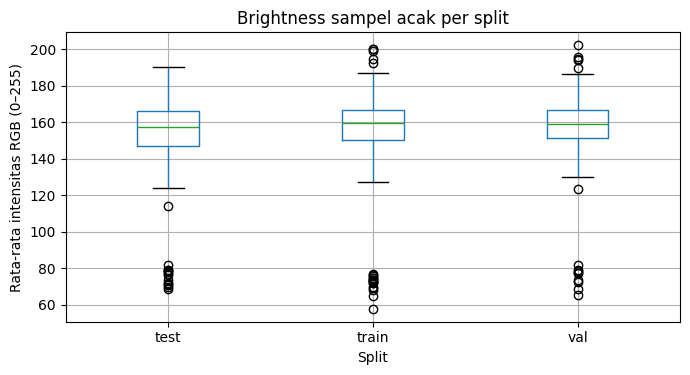

In [ ]:
# Audit tampilan dasar pada sampel acak berstrata. Ini bukan fitur training, hanya diagnosis kualitas dataset.
import random
import numpy as np

visual_records = []
rng = random.Random(RANDOM_SEED)
for model_split, disk_split in SPLITS.items():
    image_paths = [p for p in (DATASET_DIR / disk_split / "images").iterdir() if p.suffix.lower() in VALID_IMAGE_SUFFIXES]
    for image_path in rng.sample(image_paths, min(200, len(image_paths))):
        array = np.asarray(Image.open(image_path).convert("RGB"), dtype=np.float32)
        visual_records.append({
            "split": model_split, "image": image_path.name,
            "brightness": array.mean(), "red_mean": array[..., 0].mean(),
            "green_mean": array[..., 1].mean(), "blue_mean": array[..., 2].mean(),
        })
visual_eda_df = pd.DataFrame(visual_records)
visual_eda_df.to_csv(OUTPUT_DIR / "eda_visual_sample.csv", index=False)
display(visual_eda_df.groupby("split")[["brightness", "red_mean", "green_mean", "blue_mean"]].agg(["mean", "std"]).round(2))

ax = visual_eda_df.boxplot(column="brightness", by="split", figsize=(7, 4))
plt.suptitle("")
ax.set(title="Brightness sampel acak per split", xlabel="Split", ylabel="Rata-rata intensitas RGB (0–255)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "eda_brightness_by_split.png", dpi=180, bbox_inches="tight")
plt.show()

### Kondisi visual sampel

Rata-rata brightness sampel berada pada rentang **152,80–156,09** (skala 0–255), dengan standar deviasi sekitar **21–27**. Nilainya cukup serupa antar-split; ini memberi indikasi awal bahwa pencahayaan global tidak berbeda jauh antara train, validasi, dan test.

Rata-rata kanal merah lebih tinggi daripada biru pada semua split, yang wajar untuk dominasi warna objek/latar dalam data ini. Kesimpulan ini berasal dari sampel acak (maksimal 200 gambar per split), sehingga digunakan sebagai pemeriksaan cepat, bukan statistik seluruh dataset.


# 5. Explore — Distribusi kelas dan cek kebocoran duplikat persis

Bagian ini menghitung jumlah bounding box per kelas pada setiap split dan menggunakan hash SHA-256 untuk mencari file gambar yang **identik byte-per-byte** di lebih dari satu split. Duplikasi lintas split dapat membuat metrik evaluasi terlihat lebih baik dari kondisi sebenarnya karena model pernah melihat gambar yang sama saat training.

Pemeriksaan hash tidak mendeteksi gambar yang sangat mirip, hasil augmentasi, atau frame video yang berdekatan tetapi berbeda file. Karena itu, hasil “tidak ada duplikat” hanya menyimpulkan tidak ada duplikat persis dan tetap perlu dibaca bersama kebijakan augmentasi Roboflow serta asal pengambilan gambar.


,train,val,test
kurang masak,2635,757,394
masak,1959,556,271
mentah,2447,705,362
terlalu masak,2225,636,328


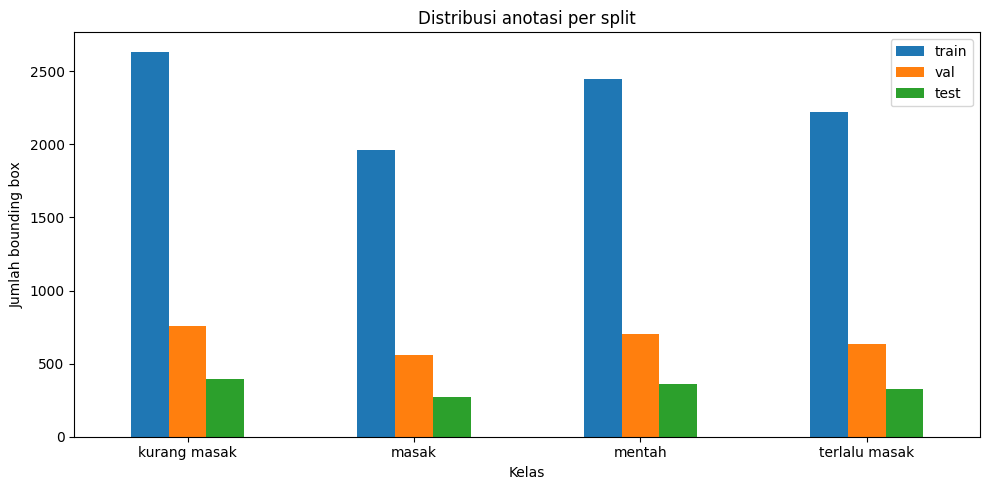

Exact duplicate lintas split: 0


In [ ]:
class_counts = defaultdict(Counter)
hash_to_splits = defaultdict(set)

def sha256_file(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()

for model_split, disk_split in SPLITS.items():
    for image_path in (DATASET_DIR / disk_split / "images").iterdir():
        if image_path.suffix.lower() not in VALID_IMAGE_SUFFIXES:
            continue
        hash_to_splits[sha256_file(image_path)].add(model_split)
        for class_id, *_ in parse_yolo_label(DATASET_DIR / disk_split / "labels" / f"{image_path.stem}.txt"):
            class_counts[model_split][CLASS_NAMES[class_id]] += 1

distribution_df = pd.DataFrame(class_counts).fillna(0).astype(int).reindex(CLASS_NAMES)
display(distribution_df)
distribution_df.to_csv(OUTPUT_DIR / "class_distribution_by_split.csv")
ax = distribution_df.plot(kind="bar", figsize=(10, 5), rot=0)
ax.set(xlabel="Kelas", ylabel="Jumlah bounding box", title="Distribusi anotasi per split")
plt.tight_layout()
plt.show()

cross_split_duplicates = {h: sorted(s) for h, s in hash_to_splits.items() if len(s) > 1}
with open(OUTPUT_DIR / "exact_cross_split_duplicates.json", "w", encoding="utf-8") as f:
    json.dump(cross_split_duplicates, f, indent=2)
print(f"Exact duplicate lintas split: {len(cross_split_duplicates)}")

### Distribusi kelas dan duplikasi

Tabel kembali mengonfirmasi bahwa pola jumlah kelas serupa pada train, validasi, dan test. Kelas `masak` memiliki anotasi paling sedikit di ketiga split, sehingga evaluasi per kelas perlu menjadi perhatian saat membandingkan model.

Hasil `Exact duplicate lintas split: 0` berarti tidak ada file gambar yang sama persis muncul di lebih dari satu split berdasarkan SHA-256. Ini mengurangi risiko kebocoran data langsung, tetapi tidak menyingkirkan kemungkinan gambar yang sangat mirip atau frame dari video yang sama.


## 6. Visual quality check

Sel ini menampilkan enam contoh acak dari split training dengan kotak dan nama kelas yang digambar di atas citra. Pemeriksaan ini bersifat manual: tujuannya memastikan posisi kotak, ukuran kotak, dan kelas terlihat masuk akal secara visual sebelum model dilatih.

Sampel memakai seed tetap (`42`), sehingga contoh yang sama dapat direproduksi saat notebook dijalankan ulang. Jika ada kesalahan label, catat nama file pada judul gambar untuk ditelusuri kembali di dataset sumber.


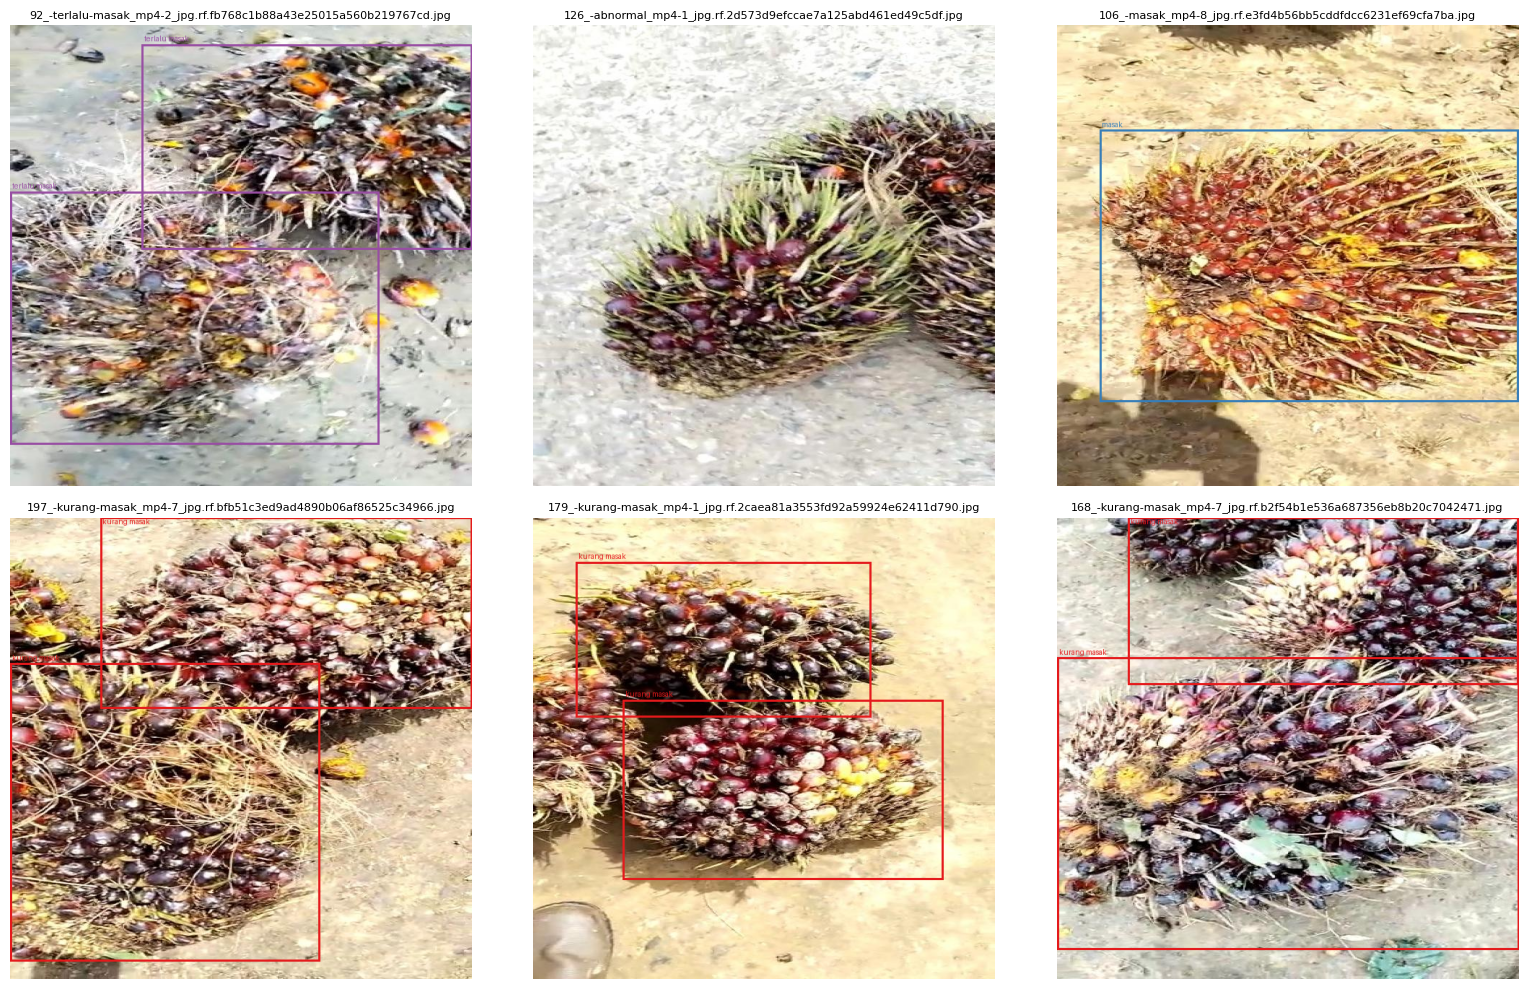

In [ ]:
PALETTE = ["#e41a1c", "#377eb8", "#4daf4a", "#984ea3"]

def show_yolo_samples(model_split="train", n=6, seed=RANDOM_SEED):
    disk_split = SPLITS[model_split]
    images = sorted(p for p in (DATASET_DIR / disk_split / "images").iterdir() if p.suffix.lower() in VALID_IMAGE_SUFFIXES)
    rng = __import__("random").Random(seed)
    selected = rng.sample(images, min(n, len(images)))
    fig, axes = plt.subplots(2, 3, figsize=(16, 10))
    for ax, image_path in zip(axes.flat, selected):
        image = Image.open(image_path).convert("RGB")
        draw = ImageDraw.Draw(image)
        width, height = image.size
        for class_id, xc, yc, bw, bh in parse_yolo_label(DATASET_DIR / disk_split / "labels" / f"{image_path.stem}.txt"):
            x1, y1 = (xc - bw / 2) * width, (yc - bh / 2) * height
            x2, y2 = (xc + bw / 2) * width, (yc + bh / 2) * height
            color = PALETTE[class_id]
            draw.rectangle((x1, y1, x2, y2), outline=color, width=3)
            draw.text((x1 + 3, max(0, y1 - 14)), CLASS_NAMES[class_id], fill=color)
        ax.imshow(image); ax.set_title(image_path.name, fontsize=8); ax.axis("off")
    for ax in axes.flat[len(selected):]: ax.axis("off")
    plt.tight_layout()

show_yolo_samples("train")

### Pemeriksaan bounding box visual

Figur menampilkan enam gambar training acak beserta bounding box dan nama kelas. Tinjau tiga hal: kotak menutup objek yang benar, nama kelas sesuai kondisi kematangan yang tampak, dan kotak tidak keluar dari batas gambar. Tidak adanya error saat gambar tampil mengonfirmasi parser label dapat membaca sampel tersebut.

Jika ditemukan anotasi yang tampak keliru, gunakan nama file pada judul subplot untuk memeriksa label sumber. Karena sampel ini kecil, pemeriksaan tambahan dengan seed atau split lain dapat dilakukan sebelum training produksi.


## 7. Transform — Konversi YOLO ke COCO untuk Faster R-CNN

Faster R-CNN memerlukan anotasi COCO. Konversi mengubah bbox YOLO dari `(x_tengah, y_tengah, lebar, tinggi)` yang ternormalisasi menjadi `(x_kiri, y_atas, lebar, tinggi)` dalam piksel. Kategori COCO memakai ID 1–4 sesuai mapping sebelumnya; ID 0 tidak diekspor sebagai objek karena merupakan background internal Faster R-CNN.

Setiap file JSON COCO memuat metadata gambar dan anotasi untuk satu split. Gambar tidak diduplikasi; `file_name` pada JSON merujuk ke nama gambar di folder `images` split asal. Saat membuat dataset PyTorch, pasangkan JSON split dengan folder gambar yang sesuai.


In [ ]:
def yolo_to_coco_bbox(xc, yc, bw, bh, image_width, image_height):
    x = (xc - bw / 2) * image_width
    y = (yc - bh / 2) * image_height
    width = bw * image_width
    height = bh * image_height
    # Clamp aman untuk floating-point rounding pada tepi gambar.
    x = max(0.0, min(x, image_width - 1))
    y = max(0.0, min(y, image_height - 1))
    width = max(1e-6, min(width, image_width - x))
    height = max(1e-6, min(height, image_height - y))
    return [round(x, 4), round(y, 4), round(width, 4), round(height, 4)]

def export_coco_split(model_split, disk_split):
    image_dir = DATASET_DIR / disk_split / "images"
    coco = {
        "info": {"description": "Palm oil maturity dataset converted from YOLO", "version": "1.0", "date_created": datetime.now(timezone.utc).isoformat()},
        "licenses": [],
        "categories": [{"id": idx + 1, "name": name, "supercategory": "palm_oil_maturity"} for idx, name in enumerate(CLASS_NAMES)],
        "images": [], "annotations": []
    }
    annotation_id = 1
    image_paths = sorted(p for p in image_dir.iterdir() if p.suffix.lower() in VALID_IMAGE_SUFFIXES)
    for image_id, image_path in enumerate(image_paths, start=1):
        with Image.open(image_path) as im:
            image_width, image_height = im.size
        coco["images"].append({"id": image_id, "file_name": image_path.name, "width": image_width, "height": image_height})
        for yolo_id, xc, yc, bw, bh in parse_yolo_label(DATASET_DIR / disk_split / "labels" / f"{image_path.stem}.txt"):
            bbox = yolo_to_coco_bbox(xc, yc, bw, bh, image_width, image_height)
            coco["annotations"].append({"id": annotation_id, "image_id": image_id, "category_id": YOLO_TO_COCO[yolo_id], "bbox": bbox, "area": round(bbox[2] * bbox[3], 4), "iscrowd": 0})
            annotation_id += 1
    target = OUTPUT_DIR / f"instances_{model_split}.json"
    with target.open("w", encoding="utf-8") as f:
        json.dump(coco, f, ensure_ascii=False, indent=2)
    return target, len(coco["images"]), len(coco["annotations"])

coco_summary = []
for model_split, disk_split in SPLITS.items():
    path, image_count, annotation_count = export_coco_split(model_split, disk_split)
    coco_summary.append({"split": model_split, "coco_json": str(path), "images": image_count, "annotations": annotation_count})
coco_summary_df = pd.DataFrame(coco_summary)
display(coco_summary_df)
coco_summary_df.to_csv(OUTPUT_DIR / "coco_export_summary.csv", index=False)

,split,coco_json,images,annotations
0,train,/content/palm_oil_model_comparison/preprocessi...,5893,9266
1,val,/content/palm_oil_model_comparison/preprocessi...,1676,2654
2,test,/content/palm_oil_model_comparison/preprocessi...,827,1355


### Hasil ekspor COCO

Tiga JSON COCO berhasil dibuat: train berisi **5.893** gambar dan **9.266** anotasi, validasi **1.676**/ **2.654**, serta test **827**/ **1.355**. Angka ini sama dengan hasil audit sebelumnya, sehingga ekspor tidak mengubah jumlah data.

Untuk Faster R-CNN, gunakan masing-masing `instances_train.json`, `instances_val.json`, dan `instances_test.json` bersama folder gambar split yang sepadan. Jangan menggabungkan JSON dan folder gambar dari split berbeda karena ID gambar dalam JSON berlaku untuk split tersebut.


## 8. Final consistency gate & training handoff

Pemeriksaan terakhir membandingkan jumlah gambar dan anotasi dalam setiap JSON COCO dengan hasil audit YOLO. Jika semua `assert` lolos, artinya tidak ada gambar atau objek yang hilang selama standardisasi dan ekspor.

Selain itu, notebook menyimpan `preprocessing_metadata.json` sebagai catatan reproduksibilitas: lokasi data, waktu pemrosesan, mapping kelas, split, dan keputusan transformasi. File ini berguna saat hasil training perlu ditelusuri kembali.


In [ ]:
for row in coco_summary:
    split_audit = audit_df[audit_df["split"] == row["split"]]
    assert row["images"] == len(split_audit)
    assert row["annotations"] == int(split_audit["boxes"].sum())

run_metadata = {
    "dataset_dir": str(DATASET_DIR),
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "image_standard": "640x640 (validated by image_audit.csv)",
    "yolo_classes": {str(i): name for i, name in enumerate(CLASS_NAMES)},
    "faster_rcnn_categories": {str(i + 1): name for i, name in enumerate(CLASS_NAMES)},
    "splits": SPLITS,
    "notes": ["YOLO label IDs are 0-based. COCO/Faster R-CNN IDs are 1-based; 0 is background.", "Polygon labels are converted to detection bounding boxes for both models.", "No augmentation, resize, or source-file deletion is performed by this notebook."]
}
with open(OUTPUT_DIR / "preprocessing_metadata.json", "w", encoding="utf-8") as f:
    json.dump(run_metadata, f, ensure_ascii=False, indent=2)

print("✓ Audit, label standardization, exploration, and COCO conversion selesai.")
print(f"YOLOv11 : gunakan {YOLO_DATA_YAML}")
print("Faster R-CNN : gunakan instances_train.json, instances_val.json, instances_test.json + folder images split terkait.")

✓ Audit, label standardization, exploration, and COCO conversion selesai.
YOLOv11 : gunakan /content/palm_oil_model_comparison/yolo_detection_ready/data_yolo_detection_ready.yaml
Faster R-CNN : gunakan instances_train.json, instances_val.json, instances_test.json + folder images split terkait.


### Status handoff training

Tanda centang menunjukkan seluruh pemeriksaan konsistensi lolos: audit, standardisasi label, EDA, dan konversi COCO selesai tanpa kehilangan jumlah gambar maupun anotasi. Dataset kini memiliki dua jalur input yang semantik kelasnya sama.

Untuk YOLOv11 gunakan `data_yolo_detection_ready.yaml`. Untuk Faster R-CNN gunakan JSON COCO per split dan folder gambar terkait. Perbedaan ID (YOLO 0–3 vs. COCO 1–4) sudah ditangani oleh file hasil preprocessing; jangan melakukan offset ID lagi saat memuat label.